[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/01-framing.ipynb)

# Recommender Systems: Framing the Problem

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Describe a ratings table as a sparse users-by-items matrix and compute its density and memory cost.</li>
<li>Tell explicit feedback (ratings) from implicit feedback (who chose what) and say what each can and cannot tell you.</li>
<li>Show, with data, that a recommender's data is not a random sample: the most-rated movies are the better-liked ones.</li>
<li>Choose a problem statement (rating prediction or top-N ranking) and defend the choice.</li>
</ul>
</div>

**Prerequisites:** the lifecycle chapter (especially [Splitting Strategy](../lifecycle/05-splitting.ipynb)) and the pandas toolkit pages. **Dataset:** MovieLens small. **Time:** about 25 minutes.

## The situation

A streaming service wants a "Because you watched..." row on its home page: **ten titles, different for every user, that the user has not seen yet.** What data do we have? Every rating any user has given to any movie. What do we need to produce? A short, ordered list per user. This track builds that, one idea per page, and tests every idea honestly on held-out data.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)

## Maths ↔ code

Collect the ratings into a matrix $R \in \mathbb{R}^{U \times I}$: row $u$ is a user, column $i$ an item, entry $r_{ui}$ the rating (blank when the user never rated the item). In code that matrix is a **sparse** `scipy` matrix, built by `rs.to_csr`, because almost every cell is blank. Its **density** is $\text{nnz} / (U \cdot I)$, which is `X.nnz / np.prod(X.shape)`.

## 1. The data as a matrix

In [2]:
ml = load_movielens()
ratings = ml.ratings
index = rs.make_index(ratings)                        # which row is which user, which column is which movie
X = rs.to_csr(ratings, index, value="rating")         # users x movies, ratings as values

n_users, n_items = X.shape
print(f"{len(ratings):,} ratings from {n_users} users on {n_items:,} movies")
print(f"matrix shape {X.shape}, {X.nnz:,} filled cells, density {X.nnz / (n_users * n_items):.2%}")
ratings.head()

100,836 ratings from 610 users on 9,724 movies
matrix shape (610, 9724), 100,836 filled cells, density 1.70%


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Out of the 5.9 million user-movie pairs, **about 1.7% are filled**. That fraction is the central fact of recommendation: for each user we know a sliver of what they think and have to say something about the other 98%.

## 2. Explicit feedback: what the ratings say

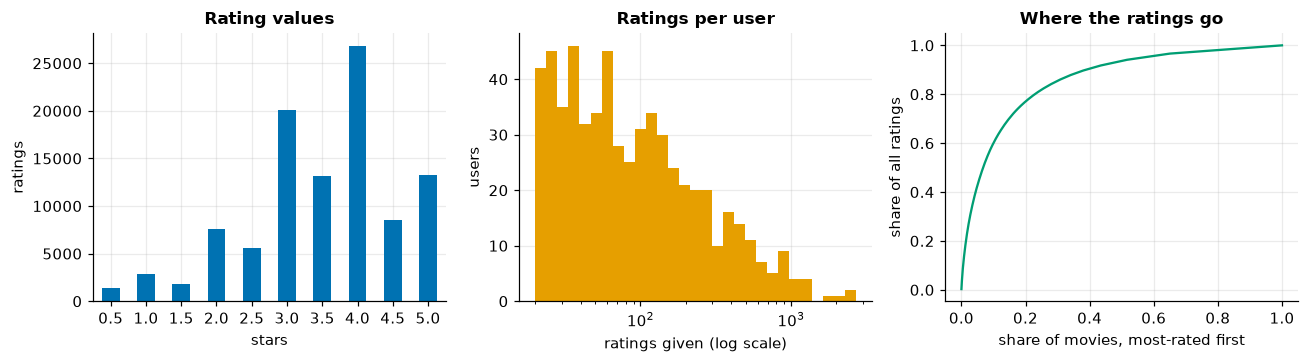

mean rating 3.50; share of ratings that are 4 stars or more: 48%
user activity: median 70.5 ratings, max 2,698
the most-rated 10% of movies hold 60% of all ratings; 35% of movies have exactly one rating


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ratings["rating"].value_counts().sort_index().plot.bar(ax=axes[0], color=style.BLUE, rot=0)
axes[0].set(title="Rating values", xlabel="stars", ylabel="ratings")

per_user = ratings.groupby("userId").size()
axes[1].hist(per_user, bins=np.logspace(np.log10(20), np.log10(per_user.max()), 30), color=style.ORANGE)
axes[1].set(xscale="log", title="Ratings per user", xlabel="ratings given (log scale)", ylabel="users")

per_item = ratings.groupby("movieId").size().sort_values(ascending=False)
share = per_item.cumsum() / per_item.sum()
axes[2].plot(np.arange(1, len(share) + 1) / len(share), share.values, color=style.GREEN)
axes[2].set(title="Where the ratings go", xlabel="share of movies, most-rated first", ylabel="share of all ratings")
plt.tight_layout(); plt.show()

top10 = share.iloc[int(0.1 * len(share)) - 1]
print(f"mean rating {ratings['rating'].mean():.2f}; share of ratings that are 4 stars or more: {(ratings['rating'] >= 4).mean():.0%}")
print(f"user activity: median {per_user.median():.1f} ratings, max {per_user.max():,}")
assert abs(top10 - 0.60) < 0.01 and abs((per_item == 1).mean() - 0.35) < 0.01        # guards the prose below
print(f"the most-rated 10% of movies hold {top10:.0%} of all ratings; {(per_item == 1).mean():.0%} of movies have exactly one rating")

Three things to take from these pictures.

- **Ratings are generous.** About half of all ratings are 4 stars or more (mean 3.50), and whole stars are more common than half stars. A "good" rating is the *normal* case, which is why the course will call 4 stars or more a "like" and why a model that recommends well-known good movies already looks respectable.
- **Activity is long-tailed.** Users rate between 20 and 2,698 movies; the median is 70.5. A few heavy users contribute a large share of the signal.
- **Attention is concentrated.** The most-rated tenth of movies holds 60% of all ratings, while 35% of movies have a single rating. For those, the data cannot say anything about *who else* might like them.

## 3. Implicit feedback: *what* was rated says as much as *how*

Ratings are **explicit** feedback: the user tells us how much they liked something. Much of the data real systems hold is **implicit**: a click, a purchase, minutes watched. It never says "disliked", only "chose". The two kinds are not as separate as they look, because even in this ratings table **the act of rating is itself an implicit signal**: people mostly rate what they chose to watch, and they choose what they expect to like.

Check it. If rating were a random sample of the catalogue, popular and obscure movies would be rated equally highly. They are not:

In [4]:
stats = ratings.groupby("movieId")["rating"].agg(["count", "mean"])
stats["popularity band"] = pd.qcut(stats["count"].rank(method="first"), 5, labels=["least rated", "2", "3", "4", "most rated"])
band = stats.groupby("popularity band", observed=True).agg(movies=("count", "size"), ratings=("count", "sum"),
                                                          mean_rating=("mean", "mean"), spread_of_means=("mean", "std"))
print(band.round(2).to_string())
share_top = band.loc["most rated", "ratings"] / band["ratings"].sum()

rho_all = stats["count"].corr(stats["mean"], method="spearman")
well_rated = stats[stats["count"] >= 10]
rho_10 = well_rated["count"].corr(well_rated["mean"], method="spearman")
assert 0.75 < share_top < 0.80 and rho_all < 0.1 < rho_10                           # guards the prose below
print(f"\nrank correlation, number of ratings vs mean rating: {rho_all:.2f} over all movies, "
      f"{rho_10:.2f} over the {len(well_rated):,} movies with at least 10 ratings")

                 movies  ratings  mean_rating  spread_of_means
popularity band                                               
least rated        1945     1945         3.22             1.06
2                  1945     2389         3.22             1.15
3                  1944     5268         3.18             0.81
4                  1945    13556         3.23             0.64
most rated         1945    77678         3.46             0.49

rank correlation, number of ratings vs mean rating: 0.04 over all movies, 0.25 over the 2,269 movies with at least 10 ratings


Read the table from top to bottom. The most-rated fifth of the movies receives **77% of all ratings** and is rated about a quarter of a star higher (3.46 against about 3.2). The other four bands look alike, and the last column explains why: the *mean* rating of a movie with one or two ratings is wildly noisy (the spread of means across such movies is above 1 star, against 0.49 for the most-rated band). That noise hides the real pattern when you correlate over all movies (0.04), and it appears once you look only at movies with at least 10 ratings (0.25): **better-liked movies are rated more often.**

Two consequences run through the whole track. First, "how many people rated it" is a strong signal in its own right, which is why a plain popularity list will turn out to be hard to beat. Second, an average over a handful of ratings must not be trusted, which is the subject of the next-but-one page.

## 4. What are we predicting? Three framings

| Framing | Question | Metric | What it ignores |
|---|---|---|---|
| **Rating prediction** | "What stars will user *u* give movie *i*?" | RMSE / MAE | Which movies we show; an accurate guess about a movie nobody will ever watch is worthless |
| **Top-N ranking** | "Which ten unseen movies should we show *u*?" | Precision/Recall@10, NDCG@10 | The exact star value |
| **Next item** | "What will *u* watch next?" | Hit rate, MRR | Everything except the very next event |

The business question above is a **ranking** question, so **this track uses top-N ranking**: for every user, rank all the movies they have not rated and ask whether the ones they later rate **4 stars or more** are near the top. (Rating prediction gets its own, sobering, scene on [page 4](04-neighbourhood.ipynb).)

## 5. What goes wrong: the dense matrix does not scale

In [5]:
dense_gb = n_users * n_items * 4 / 1e9
sparse_mb = (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6
print(f"this data, dense float32: {dense_gb * 1000:,.0f} MB | sparse (CSR): {sparse_mb:.1f} MB")

# the size of the Netflix Prize matrix (480,000 users, 17,700 films), if it were stored densely
users_big, items_big = 480_000, 17_700
print(f"{users_big:,} users x {items_big:,} items, dense float32: {users_big * items_big * 4 / 1e9:,.0f} GB")

this data, dense float32: 24 MB | sparse (CSR): 0.8 MB
480,000 users x 17,700 items, dense float32: 34 GB


The dense version of this small data set is 24 MB and the sparse one under 1 MB, a factor of about 30. At the size of the Netflix Prize matrix the dense version would need 34 GB, while the sparse one still grows only with the number of ratings.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>Never call <code>.toarray()</code> or <code>.todense()</code> on the whole interaction matrix of a real system. The course does it on this small data set because it fits; the models you will meet are written to work on the sparse form, one block of users at a time.</p>
</div>

## Decision guide

| Situation | Frame it as | Why |
|---|---|---|
| You show a short list ("top 10", a carousel) | Top-N ranking | The list is what the user sees; only the order near the top matters |
| Users give stars and the star value is the product (e.g. a predicted-rating label) | Rating prediction, *and* check ranking | RMSE says nothing about which items win the top slots |
| You only have clicks, views or purchases | Implicit feedback, ranking ([page 6](06-implicit-retail.ipynb)) | There are no stars; "chose" is all there is |
| Users have almost no history | Cold start ([page 7](07-cold-start.ipynb)) | Collaborative signals need history |

## Check yourself

<details class="question">
<summary>1. A user has rated 50 of 9,724 movies. How would you describe what we know about the other 9,674?</summary>

We know nothing directly about those cells, and the missing ones are **not missing at random**: users rate what they chose to watch. A blank is a mixture of "never saw it", "saw it and did not bother to rate" and "would hate it". Treating every blank as a dislike is wrong, and so is treating blanks as if they had been sampled uniformly; later pages handle this in different ways.

</details>

<details class="question">
<summary>2. Why is "predict the rating" a risky target for a recommender?</summary>

A model can reduce its RMSE by being slightly better on thousands of ordinary pairs while still putting the wrong ten movies at the top of every list. Page 4 measures exactly this on the data.

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): what share of users have rated more than 100 movies, and how many of the filled cells do they own?</summary>

```python
heavy = per_user[per_user > 100]
print(f"{len(heavy) / len(per_user):.0%} of users own {heavy.sum() / per_user.sum():.0%} of the ratings")
```

About 40% of users have rated more than 100 movies and between them they own about 83% of all ratings. A collaborative model learns mostly from those users, so a typical light user is served worse than a score averaged over all *ratings* suggests (the next page averages over users to avoid exactly that).

</details>

<details class="question">
<summary>Exercise 2 (medium): is the mean rating of a user related to how many movies they rated?</summary>

```python
u = ratings.groupby("userId")["rating"].agg(["count", "mean"])
print(u["count"].corr(u["mean"], method="spearman"))
```

The rank correlation is about -0.14: a weak negative. Heavy raters are slightly harsher, so "rates a lot" and "rates high" are different things. User-level habits like this are why later models subtract a per-user average before comparing users.

</details>

<details class="question">
<summary>Exercise 3 (medium): make a plot of the number of ratings per calendar year. What does it say about using time to split the data?</summary>

```python
ratings.assign(year=pd.to_datetime(ratings["timestamp"], unit="s").dt.year).groupby("year").size().plot.bar()
```

Ratings are spread over more than twenty years, with different users active in different periods. A single calendar cut-off would leave most users with no history at all, which is why the next page splits *within* each user.

</details>

## Recap

- A ratings table is a **sparse users-by-items matrix**; here only about 1.7% of cells are filled.
- Activity is **long-tailed**: a few heavy users and a few blockbuster movies carry most of the data.
- Data is **not a random sample**: what gets rated is itself a signal, and the most-rated movies are the better-liked ones (once the noisy means of rarely-rated movies are set aside).
- We frame the task as **top-N ranking of unseen items**, scored by whether later well-liked items rank near the top.
- Next: the evaluation protocol, because every later page is only as honest as that protocol.